# Seeing the challenge: cones, cuts, rewrites

The planner's decisions are invisible in code: which gates each
observable really needs, where channel cuts fall, what rewriting
removes. This notebook draws them, on the QAOA path (4 qubits,
3 requests), using `benchmarks/circuit_viz.py`.

In [1]:
%matplotlib inline
import os

for key in ("QULACS_NUM_THREADS", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "benchmarks"))

from lazyqc import CutOptions, Program, calibrate_batch, plan_all
from lazyqc.cutting import components
from lazyqc.fixtures import load_fixture
from lazyqc.ir import Gate, Pauli
from lazyqc.passes import causal_cone
from lazyqc.plan import Task
from circuit_viz import cone_indices, draw_circuit

## The full circuit

QAOA path from the frozen fixture: Hadamards, alternating CX ladders
and RZ rotations. Every gate below *could* matter — the question is
which ones each observable actually needs.

17 gates on 4 qubits


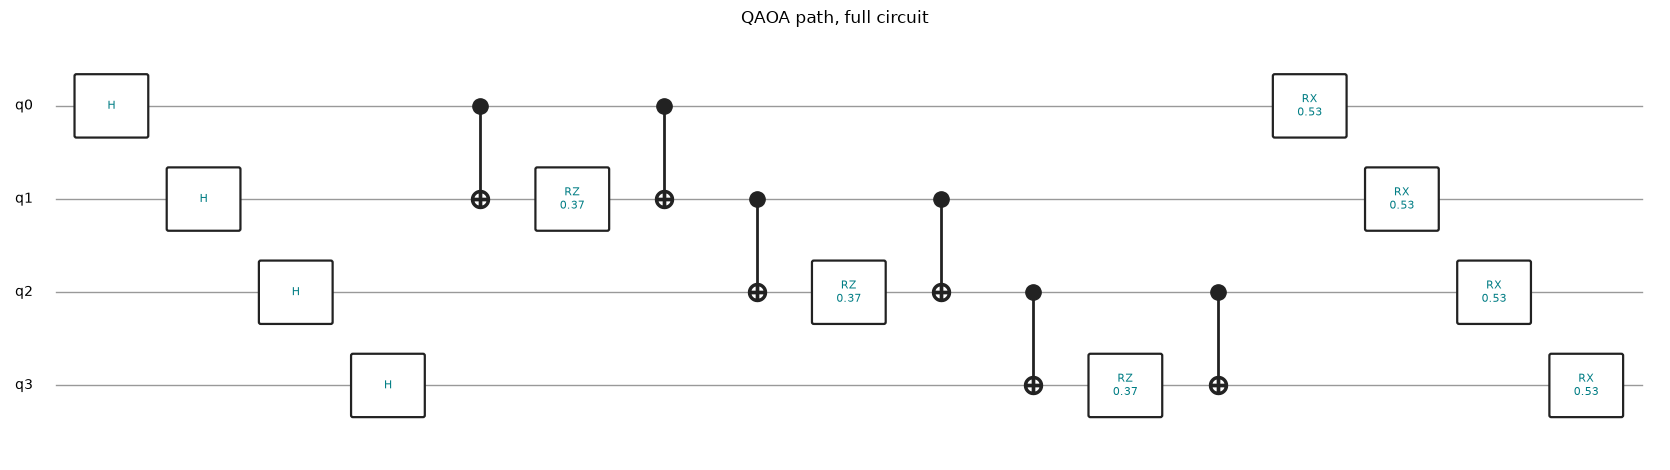

In [2]:
fixture, cases = load_fixture(ROOT / "benchmarks/p4_p5.json")
case = next(c for c in cases if c["name"] == "qaoa_path")
ops = []
for op in case["operations"]:
    if "angle_radians" in op:
        ops.append(Gate(op["gate"], tuple(op["qubits"]), op["angle_radians"]))
    else:
        ops.append(Gate(op["gate"], tuple(op["qubits"])))
program = Program(case["qubits"], tuple(ops))
resolved = program.resolved_operations()
print(f"{len(resolved)} gates on {program.n_qubits} qubits")
draw_circuit(program, title="QAOA path, full circuit")[0]

## One observable, one cone

Backward scan from the observable support: a gate disjoint from the
active wires cancels exactly and is dropped (faded). Each request keeps
only its sufficient subcircuit — note how much already disappears.

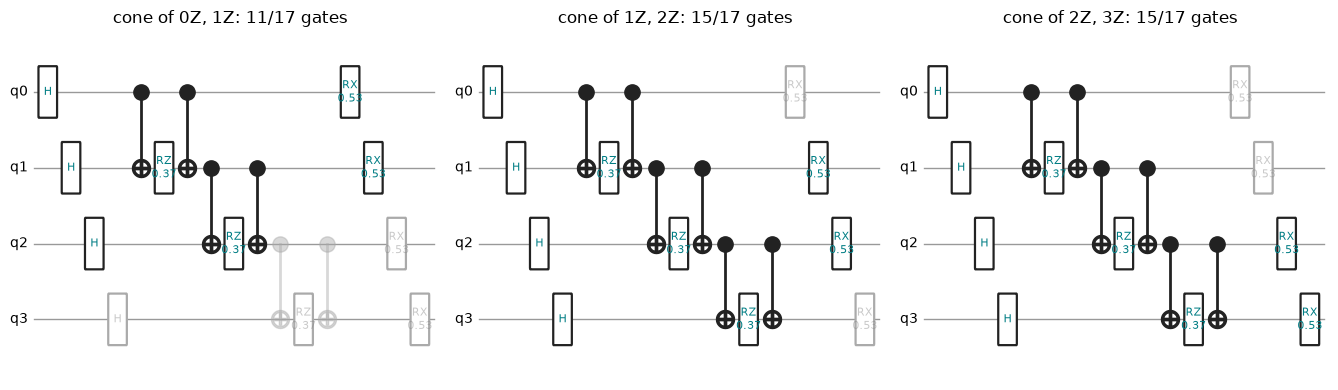

In [3]:
labels = [", ".join(f"{f['qubit']}{f['pauli']}" for f in r["observable"]) for r in case["requests"]]
fig, axes = plt.subplots(1, len(labels), figsize=(4.5 * len(labels), 4))
for ax, k in zip(axes, range(len(labels))):
    text = labels[k]
    factors = tuple((f["qubit"], f["pauli"]) for f in case["requests"][k]["observable"])
    keep = cone_indices(resolved, Pauli(factors))
    draw_circuit(program, ax=ax, keep=keep, title=f"cone of {text}: {len(keep)}/{len(resolved)} gates")
fig.tight_layout()
fig

## Where the planner cuts

Joint planning (B5) with at most two CX cuts per group. Each panel is one
selected group: its retained cone, the cut CX gates (dashed), and the
fragment wire bands. Cuts are exact channel replacements — smaller
states at the price of more fragment experiments. Runs with
`optimization="none"` so panel indices match the drawn circuits exactly
(ZX variants add alternatives through the same mechanism).

In [4]:
width = case["fragment_width"]
model, _ = calibrate_batch(widths=(1, 2, 3, 4, 6, 8), repeats=3)
options = CutOptions(max_fragment_qubits=width, max_cuts=case["max_cuts"], **fixture["cut_limits"])
requests = []
for r in case["requests"]:
    obs = {f["qubit"]: f["pauli"] for f in r["observable"]}
    requests.append(program.expectation(obs))
plan = plan_all(
    requests,
    cutting=replace(options, search="joint"),
    optimization="none",
    strategy="auto",
    cost_model=model,
    workers=1,
    max_state_qubits=width,
    max_state_bytes=16 * 2**width,
    total_state_bytes=32 * 2**width,
)
print(f"selected: {len(plan.selected.tasks)} unique experiments")
for group in plan.selected.groups:
    outputs = sorted({formula.output for formula in group.formulas})
    support = sorted({q for o in outputs for q, _ in requests[o].observable.factors})
    wires, cone = causal_cone(resolved, Pauli(tuple((q, "Z") for q in support)))
    task = Task(tuple(wires), tuple(cone), tuple((o, requests[o].observable) for o in outputs))
    parts = components(task, tuple(group.cut_indices))
    fragments = {q: i for i, part in enumerate(parts) for q in part}
    print(f"requests {outputs}: cuts={list(group.cut_indices)}, fragments={len(parts)}")

selected: 67 unique experiments
requests [0, 1, 2]: cuts=[7, 9], fragments=2


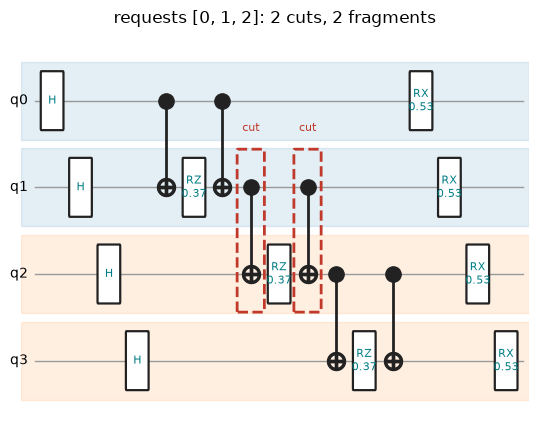

In [5]:
groups = list(plan.selected.groups)
fig, axes = plt.subplots(1, len(groups), figsize=(5.5 * len(groups), 4.5))
if len(groups) == 1:
    axes = [axes]
for ax, group in zip(axes, groups):
    outputs = sorted({formula.output for formula in group.formulas})
    support = sorted({q for o in outputs for q, _ in requests[o].observable.factors})
    wires, cone = causal_cone(resolved, Pauli(tuple((q, "Z") for q in support)))
    task = Task(tuple(wires), tuple(cone), tuple((o, requests[o].observable) for o in outputs))
    parts = components(task, tuple(group.cut_indices))
    fragments = {q: i for i, part in enumerate(parts) for q in part}
    keep = set(range(len(cone)))
    sub = Program(program.n_qubits, tuple(cone))
    draw_circuit(
        sub, ax=ax, keep=keep, cuts=set(group.cut_indices), fragments=fragments,
        title=f"requests {outputs}: {len(group.cut_indices)} cuts, {len(parts)} fragments",
    )
fig.tight_layout()
fig

## What rewriting removes

Local simplification cancels adjacent inverses and exact zero rotations
(no approximate merging). A crafted circuit makes each rule visible: the
$H$ pair and the $RY(0.3)/RY(-0.3)$ pair cancel, $RZ(0)$ vanishes, while
$RY(0.3)/RY(0.2)$ do *not* merge — different angles, both stay.

gates: 8 -> 3


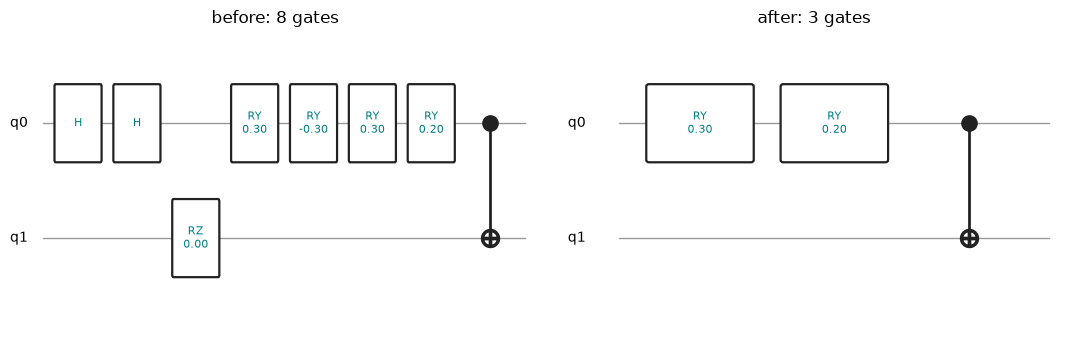

In [6]:
from lazyqc.rewrites import local_simplify

messy = Program(2).h(0).h(0).rz(1, 0.0).ry(0, 0.3).ry(0, -0.3).ry(0, 0.3).ry(0, 0.2).cx(0, 1)
before = messy.resolved_operations()
after = local_simplify(before)
print(f"gates: {len(before)} -> {len(after)}")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.5))
draw_circuit(messy, ax=left, title=f"before: {len(before)} gates")
draw_circuit(Program(2, tuple(after)), ax=right, title=f"after: {len(after)} gates")
fig.tight_layout()
fig

## What the pictures teach

- Cones prune before anything is simulated — but support analysis is
  conservative (a commuting gate is still retained).
- Cuts trade width for count: each dashed CX multiplies fragment
  experiments (~10 branches each); joint planning shares that work
  across requests (148 → 67 tasks on this path).
- Rewrites shift structure before cones are even computed — which is why
  structural reuse must key on rewritten topology, never assumed plans.
- Nothing here samples: every expectation is exact up to floating point.